<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_4_Tree_Based_Methods/Projects/Instructions/Project.4-Spotify/Titanic_Pass_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Data Collection/Sources


### Load Modules

In [ ]:
# Load Pandas, Numpy, and Matplotlib modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score

import requests

from google.colab import userdata
import os

### Authenticate to Hugging Face


In [ ]:
# Retrieve the token from Colab's secret manager
os.environ["HF_TOKEN"] = userdata.get('hf_token')
_ = os.environ["HF_TOKEN"]
f"{_[:5]} ... {_[-3:]}"

'hf_as ... mJe'

In [ ]:
os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account = os.environ["HF_ACCOUNT"]
hf_account


'ericbdf7'

In [ ]:
hf_repo = "Data_Science-22"
os.environ["HF_REPO"] = hf_repo
hf_repo


'Data_Science-22'

In [ ]:
# Log in automatically without an interactive prompt
! hf auth login --token $HF_TOKEN


The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Read parquet from Hugging Face


In [ ]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/housing_saleprice.parquet"
hf_url


'https://huggingface.co/datasets/ericbdf7/Data_Science-22/resolve/main/housing_saleprice.parquet'

In [ ]:
df3 = pd.read_parquet( hf_url )
df3.shape


(1984, 119)

In [ ]:
df3.iloc[:,:5].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1984 entries, 0 to 1983
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   SalePrice       1984 non-null   int64  
 1   Overall Qual    1984 non-null   int64  
 2   Overall Cond    1984 non-null   int64  
 3   Bsmt Full Bath  1984 non-null   float64
 4   Bsmt Half Bath  1984 non-null   float64
dtypes: float64(2), int64(3)
memory usage: 77.6 KB


In [ ]:
X_features = df3.drop(columns=['SalePrice']).copy()
X_features

,Overall Qual,Overall Cond,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,TotRms AbvGrd,Fireplaces,...,Garage Type_BuiltIn,Garage Finish_RFn,Garage Finish_Unf,Garage Qual_Gd,Garage Qual_TA,Paved Drive_Y,Sale Type_ConLD,Sale Type_New,Sale Type_WD,Sale Condition_Partial
0,4,3,1.0,0.0,1,0,3,1,5,0,...,0,0,1,0,1,0,0,0,1,0
1,6,6,0.0,0.0,1,1,3,1,6,1,...,0,0,1,0,1,0,0,0,1,0
2,8,5,1.0,0.0,2,1,3,1,7,1,...,0,1,0,0,1,1,0,0,1,0
3,7,9,1.0,0.0,1,0,3,1,6,0,...,0,1,0,0,1,1,0,0,1,0
4,5,5,0.0,0.0,1,0,3,1,5,1,...,0,0,1,0,1,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1979,6,6,0.0,0.0,1,0,3,1,6,1,...,0,0,1,0,1,1,0,0,1,0
1980,7,6,1.0,0.0,1,1,1,1,4,0,...,0,0,1,0,1,1,0,0,1,0
1981,8,5,1.0,0.0,1,0,1,1,4,2,...,0,0,0,0,1,1,0,0,1,0
1982,6,5,0.0,0.0,2,0,3,1,7,1,...,0,1,0,0,1,1,0,0,1,0


In [ ]:
y_target = df3['SalePrice'].copy()
y_target

,SalePrice
0,115400
1,141000
2,254000
3,155000
4,125000
...,...
1979,114500
1980,162000
1981,211500
1982,165000


### Backup

In [ ]:
df = df3.copy()

# Decision Tree Classification

### Max Depth = 3

In [ ]:
numLoops = 10
rmspe_scores = np.zeros(numLoops)

for idx in range(numLoops):
    X_train, X_test, y_train, y_test = train_test_split(
        X_features, y_target, test_size=0.2, random_state=idx
    )
    model = DecisionTreeRegressor(max_depth=3, random_state=idx)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmspe_scores[idx] = np.sqrt(np.mean(((y_test - y_pred) / y_test) ** 2))

print(f"Mean CV RMSPE: {rmspe_scores.mean():.4f}")

Mean CV Accuracy: 0.0113


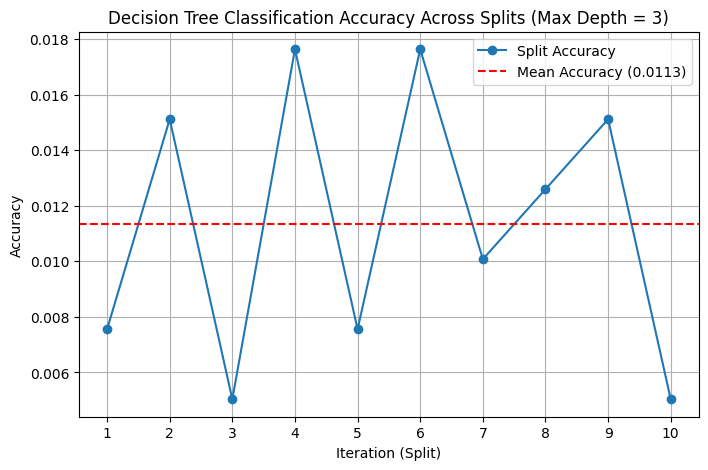

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, numLoops + 1), rmspe_scores, marker='o', label='Split RMSPE')
plt.axhline(rmspe_scores.mean(), color='red', linestyle='--', label=f'Mean RMSPE ({rmspe_scores.mean():.4f})')
plt.xlabel('Iteration (Split)')
plt.ylabel('RMSPE')
plt.title('Decision Tree Regression RMSPE Across Splits (Max Depth = 3)')
plt.xticks(range(1, numLoops + 1))
plt.legend()
plt.grid(True)
plt.show()

### Choose Max Depth

In [ ]:
max_depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
rmspe_depth = np.zeros(len(max_depths))
std_depth = np.zeros(len(max_depths))

numLoops = 10

for n, depth in enumerate(max_depths):
    rmspe_scores = np.zeros(numLoops)
    for idx in range(0, numLoops):
        X_train, X_test, y_train, y_test = train_test_split(
            X_features, y_target, test_size=0.2, random_state=idx
        )
        model = DecisionTreeRegressor(max_depth=depth, random_state=idx)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        rmspe_scores[idx] = np.sqrt(np.mean(((y_test - y_pred) / y_test) ** 2))

    rmspe_depth[n] = rmspe_scores.mean()
    std_depth[n] = rmspe_scores.std(ddof=1)

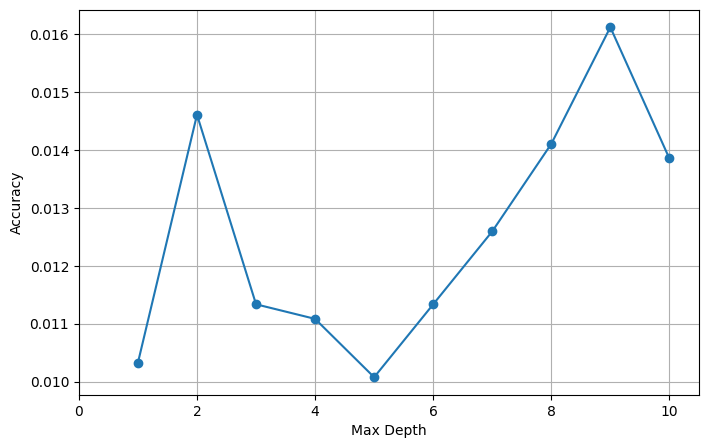

In [ ]:
# Plot the result
plt.figure(figsize=(8, 5))
plt.plot(max_depths, rmspe_depth, marker='o')
plt.xlabel('Max Depth')
plt.ylabel('RMSPE')
plt.xlim(0, 10.5)
plt.grid()
plt.show()


In [ ]:
# Display is the best depth value
best_depth = max_depths[np.argmin(rmspe_depth)]
print(f"Best Max Depth: {best_depth} (RMSPE: {rmspe_depth.min():.4f})")

Best Max Depth: 9 (Accuracy: 0.0161)


### Max Depth = Chosen

In [ ]:
numLoops = 10
rmspe_scores = np.zeros(numLoops)

for idx in range(numLoops):
    X_train, X_test, y_train, y_test = train_test_split(
        X_features, y_target, test_size=0.2, random_state=idx
    )
    model = DecisionTreeRegressor(max_depth=best_depth, random_state=idx)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmspe_scores[idx] = np.sqrt(np.mean(((y_test - y_pred) / y_test) ** 2))

print(f"Mean CV RMSPE: {rmspe_scores.mean():.4f}")


Mean CV Accuracy: 0.0161


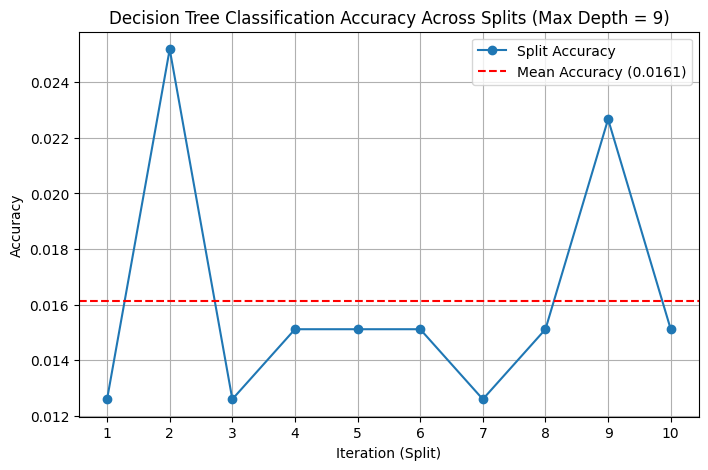

In [ ]:
# Plot the result
plt.figure(figsize=(8, 5))
plt.plot(range(1, numLoops + 1), rmspe_scores, marker='o', label='Split RMSPE')
plt.axhline(rmspe_scores.mean(), color='red', linestyle='--', label=f'Mean RMSPE ({rmspe_scores.mean():.4f})')
plt.xlabel('Iteration (Split)')
plt.ylabel('RMSPE')
plt.title(f'Decision Tree Regression RMSPE Across Splits (Max Depth = {best_depth})')
plt.xticks(range(1, numLoops + 1))
plt.legend()
plt.grid(True)
plt.show()

# Visualize the Decision Tree

In [ ]:
import graphviz
from IPython.display import display
from sklearn import tree

In [ ]:
# Option 1
display(
  graphviz.Source(
    tree.export_graphviz(
      model,
      feature_names = X_features.columns,
      filled = True,
    )
  )
)


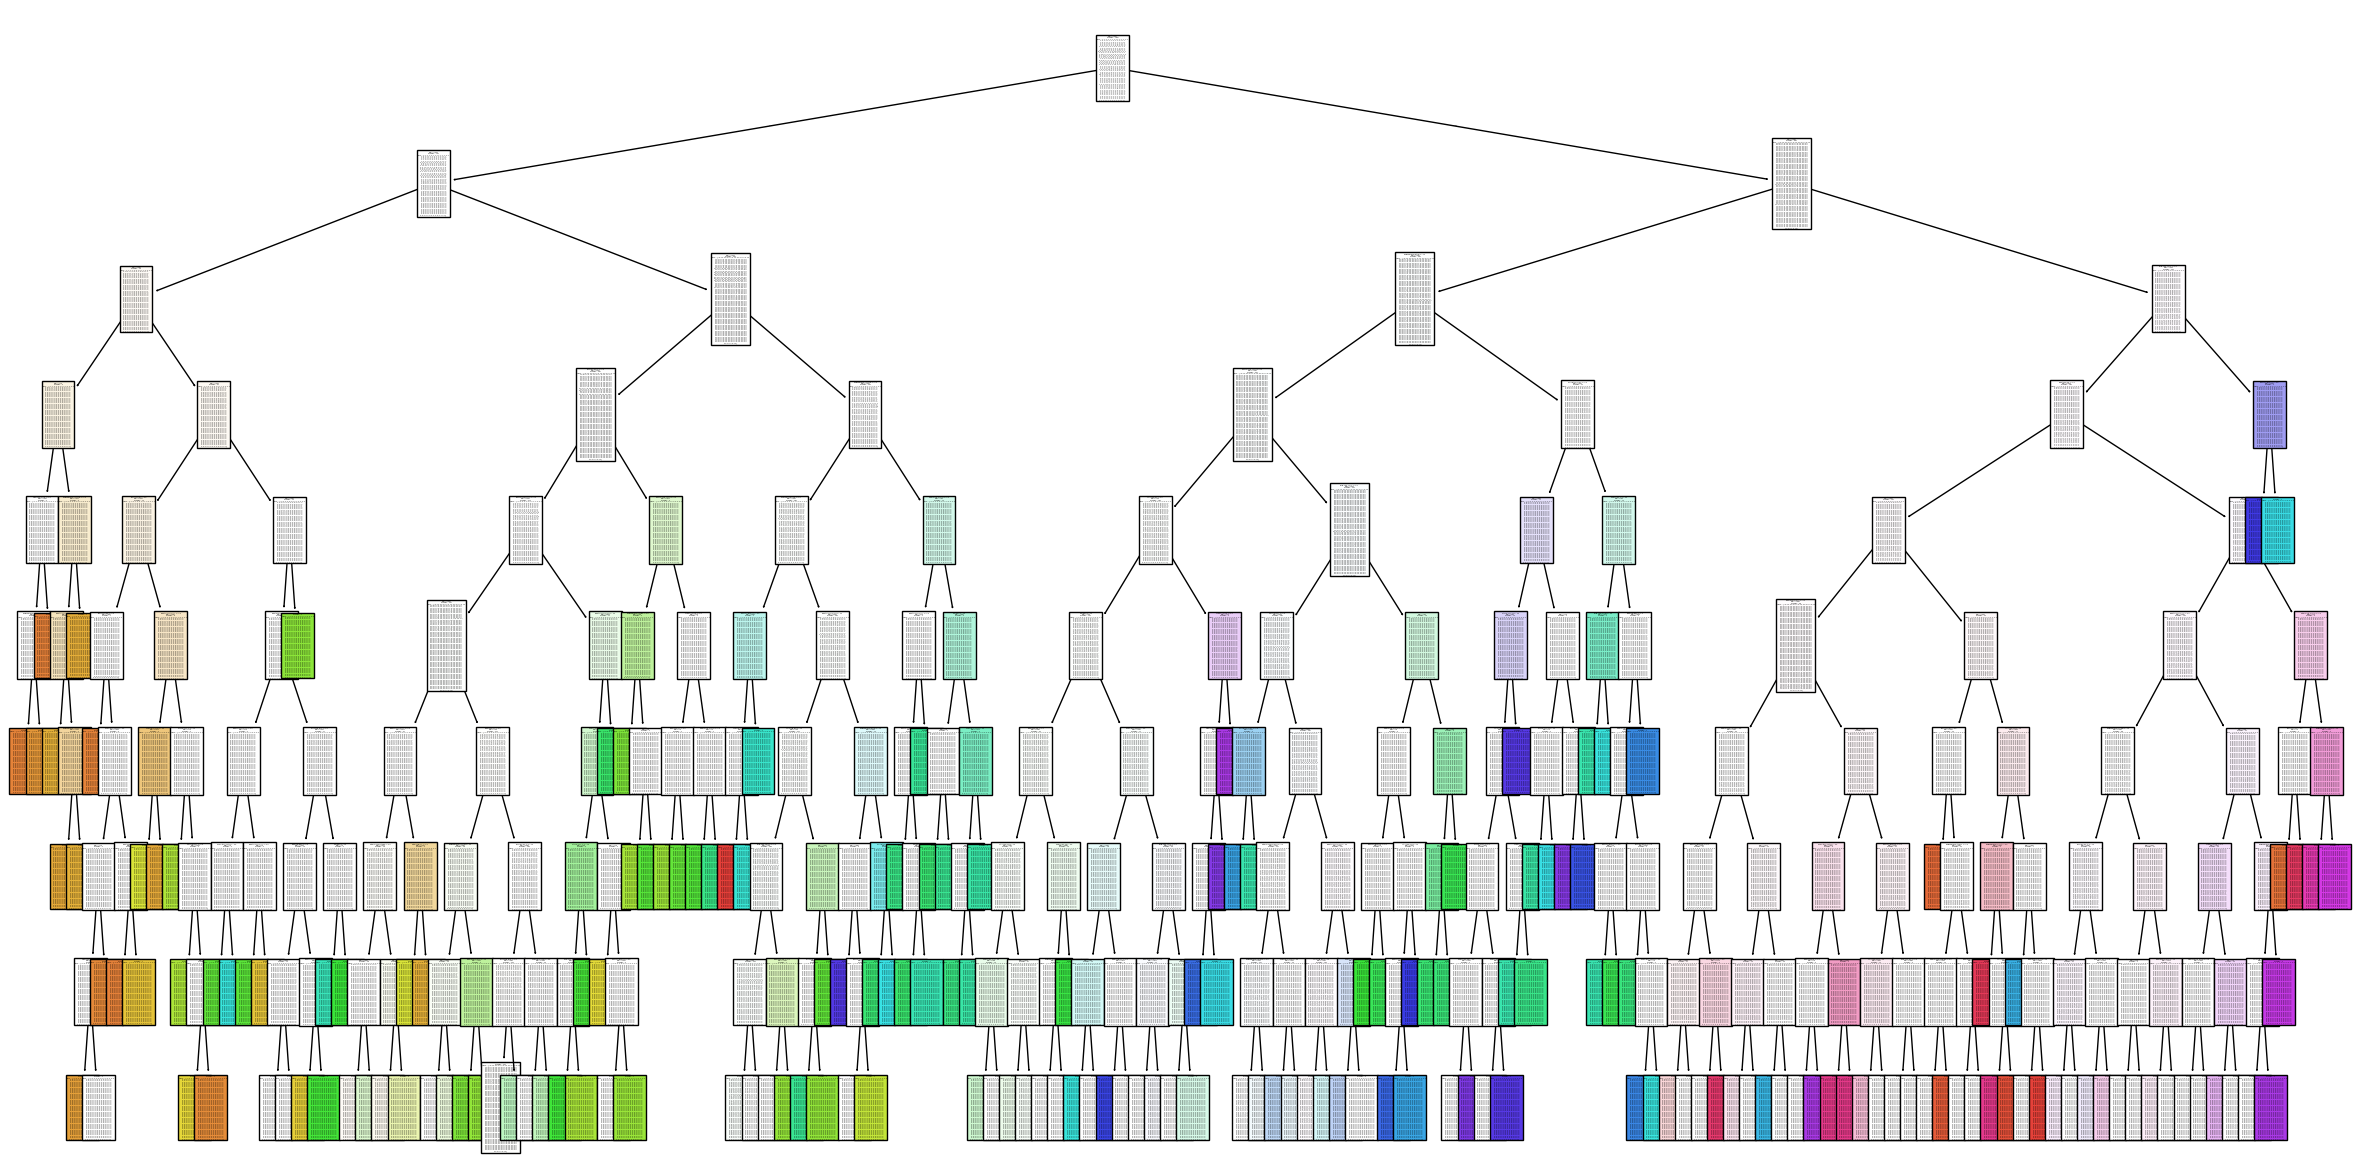

In [ ]:
# Option 2
plt.figure(figsize=(30,15))
tree_plot = tree.plot_tree(
  model,
  feature_names = X_features.columns,
  filled=True,
)


## Find Important Predictors

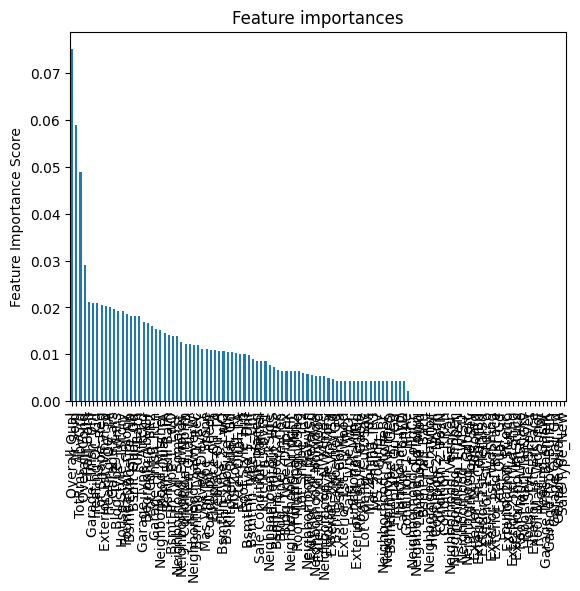

In [ ]:
importances = model.feature_importances_
tree_importances = pd.Series( importances, index = X_features.columns )

plt.figure()
# tree_importances.plot.bar()
tree_importances.sort_values( ascending = False ).plot.bar()
plt.title("Feature importances")
plt.ylabel('Feature Importance Score') ;


In [ ]:
( tree_importances.sort_values( ascending = False ) * 100 ).cumsum()


,0
Overall Qual,7.496459
Yr Sold,13.377930
TotRms AbvGrd,18.266027
Overall Cond,21.175322
Half Bath,23.283710
...,...
Garage Type_Basment,100.000000
Garage Type_BuiltIn,100.000000
Garage Qual_Gd,100.000000
Garage Qual_TA,100.000000
